# Breaching model: propeller-induced breaching at the harbour entrance spit in Sisal

Model chain, equations and assumptions are described in the Method section of the report. Report equation labels are given in brackets, e.g. [eq:Scour].

Flow: **1** inputs → **2** soil/breach mechanism → **3** efflux velocity → **4** scour → **5** breach march → **6** one vessel configuration → **7** report figures → **8** breach length, volume, released mass and duration → **9** field experiment: OBS against scour

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from dataclasses import dataclass, replace
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.transforms import offset_copy

_trapz = getattr(np, "trapezoid", None) or np.trapz

## 1. Inputs

Site, vessel and soil characteristics.

In [2]:
# -----------------------------------------------------------------------------
# 1a. Soil (sample NS1)
# -----------------------------------------------------------------------------
GS = 2.72                   # [-]     specific gravity of carbonate sand (Spagnoli 2015)
RHO_W = 1022.0              # [kg/m3] density of seawater at 30 C
RHO_MIN = 1236.0            # [kg/m3] minimum index density (ASTM D4254, method C)
RHO_MAX = 1412.0            # [kg/m3] maximum index density (ASTM D4253, method C)

# Porosity limits [eq:VoidRatio, eq:Porosity]
E_MIN, E_MAX = GS * RHO_W / RHO_MAX - 1, GS * RHO_W / RHO_MIN - 1
N_MIN, N_MAX = E_MIN / (1 + E_MIN), E_MAX / (1 + E_MAX)

# n0 cases: relative density Dr between n_max and n_min
N0_CASES_DR = {'dense': 0.75, 'intermediate': 0.50, 'loose': 0.25}

SOIL_INPUTS = dict(         # same fields, same order as SoilParams (section 2)
    # grain size
    D50=227e-6,             # [m]     median grain size (PSD of NS1)
    D15=127e-6,             # [m]     15th percentile grain size (PSD of NS1)
    # strength and packing
    phi_deg=36.1,           # [deg]   internal friction angle, approximated by the angle of repose
    n0=N_MAX - N0_CASES_DR['intermediate'] * (N_MAX - N_MIN),   # [-] reference for the checks only
    nl=N_MAX,               # [-]     porosity after dilation, n_l = n_max
    # densities
    rho_s=2720.0,           # [kg/m3] particle density (Gs = 2.72)
    rho_w=RHO_W,            # [kg/m3] density of seawater
    # constants
    g=9.81,                 # [m/s2]  gravitational acceleration
    nu=0.822e-6,            # [m2/s]  kinematic viscosity of seawater at 30 C
    # calibration
    empirical_coeff=1623.0, # [-]     fill-slope coefficient, Alhaddad et al. (2023) Eq. 3 (D50 in m)
)

# -----------------------------------------------------------------------------
# 1b. Vessel (field survey of the Sisal fleet)
# -----------------------------------------------------------------------------
VESSEL_CASES = {
    'low':     dict(Pt_hp=40.0, Dp=0.26),
    'central': dict(Pt_hp=60.0, Dp=0.28),
    'high':    dict(Pt_hp=85.0, Dp=0.32),
}
AXIS_DEPTH = 0.30                           # [m] propeller axis depth z_p, measured at rest

# -----------------------------------------------------------------------------
# 1c. Site: seaward slope of the spit (still water level, no tide)
# -----------------------------------------------------------------------------
H_TOE = 0.80                                    # [m] water depth at the toe
SLOPE_HEIGHT = H_TOE                            # [m] submerged slope height; the march stops at the water level
BETA_TOP_LEVELS = [10.0, 15.0, 20.0]            # [deg] slope angle, not measured; tested range

# -----------------------------------------------------------------------------
# 1d. Breach face and mode
# -----------------------------------------------------------------------------
BETA_BREACH = 90.0                          # [deg] breach-face angle, vertical (assumption)
MARGINAL_BAND = (0.8, 1.2)                  # S/H_crit within this band -> 'marginal'

# -----------------------------------------------------------------------------
# 1e. Regime plots
# -----------------------------------------------------------------------------
REGIME_PT = np.array([c['Pt_hp'] for c in VESSEL_CASES.values()])   # [hp] surveyed engines, each with its measured Dp
REGIME_FP = np.round(np.arange(0.1, 1.01, 0.1), 2)                  # [-] power fraction

## 2. Soil: breach velocity and critical breach height

Breaching mechanism. The n0 cases follow from the relative density between n_min and n_max.

In [3]:
@dataclass
class SoilParams:
    # No defaults: every field must come from SOIL_INPUTS, so a missing or misspelled key raises an error.
    # grain size
    D50: float                          # [m] median grain size
    D15: float                          # [m] 15th percentile grain size
    # strength and packing
    phi_deg: float                      # [deg] friction angle
    n0: float                           # [-] in-situ porosity
    nl: float                           # [-] porosity after dilation (n_max)
    # densities
    rho_s: float                        # [kg/m3] particle density
    rho_w: float                        # [kg/m3] water density
    # constants
    g: float                            # [m/s2] gravity
    nu: float                           # [m2/s] kinematic viscosity of water
    # calibration
    empirical_coeff: float              # [-] fill-slope coefficient (1623, Alhaddad Eq. 3)

    @property
    def Delta(self) -> float:
        # Relative submerged density [-]
        return (self.rho_s - self.rho_w) / self.rho_w

    def permeability(self, n: float) -> float:
        # Kozeny-Carman permeability at porosity n [m/s], van Rhee & Bezuijen (1998) Eq. 7
        return (self.g / (160 * self.nu)) * self.D15**2 * (n**3 / (1 - n)**2)

    def is_dilative(self) -> bool:
        # Breaching needs n0 < nl
        return self.n0 < self.nl

    def breach_velocity(self, beta_breach_deg: float = 90.0) -> float:
        '''
        Breach velocity [m/s], Alhaddad et al. (2023) Eq. 9.
        Returns 0 if beta_breach <= phi or n0 >= nl.
        '''
        if not self.is_dilative():
            return 0.0
        phi, beta = np.radians(self.phi_deg), np.radians(beta_breach_deg)
        if beta <= phi:
            return 0.0
        k_l = self.permeability(self.nl)
        return ((1 - self.nl) / (self.nl - self.n0)) * k_l * (1 - self.n0) * self.Delta * np.sin(beta - phi) / np.sin(phi)

    def fill_slope_tan(self, s: float) -> float:
        # tan(beta_fill) = 1623 D50^0.92 s^-0.39 for sand flux s [kg/(m s)], Alhaddad Eq. 3. Clipped to [1, 89] deg.
        if s <= 0:
            return np.tan(np.radians(89.0))
        i = self.empirical_coeff * self.D50 ** 0.92 * s ** -0.39
        return float(np.clip(i, np.tan(np.radians(1.0)), np.tan(np.radians(89.0))))

    def critical_breach_height(self, beta_top_deg: float, beta_breach_deg: float = 90.0) -> float:
        '''
        Critical breach height [m], Alhaddad et al. (2023) Eq. 8.
        Exponent 1/0.39 (paper: 2.6), so H_crit coincides with the sign change of dH/dx in march_breach().
        Returns inf if no breaching is possible.
        '''
        vb = self.breach_velocity(beta_breach_deg)
        if vb <= 0:
            return np.inf
        a = self.empirical_coeff * self.D50 ** 0.92
        return (a / np.tan(np.radians(beta_top_deg))) ** (1 / 0.39) / (vb * self.rho_s * (1 - self.n0))


soil_sisal = SoilParams(**SOIL_INPUTS)


def n0_from_dr(dr: float, n_min: float = N_MIN, n_max: float = N_MAX) -> float:
    '''In-situ porosity for relative density Dr: n0 = n_max - Dr (n_max - n_min)'''
    return n_max - dr * (n_max - n_min)


N0_CASES = {name: n0_from_dr(dr) for name, dr in N0_CASES_DR.items()}
SOIL_CASES = {name: replace(soil_sisal, n0=n0) for name, n0 in N0_CASES.items()}

print(f"Sisal sand: D50 = {soil_sisal.D50*1e6:.0f} um, D15 = {soil_sisal.D15*1e6:.0f} um, "
      f"e_min = {E_MIN:.3f}, e_max = {E_MAX:.3f}, n_min = {N_MIN:.3f}, n_max = {N_MAX:.3f}")
print("H_crit [m] per slope angle and n0 case (beta_breach = 90 deg):")
pd.DataFrame({f"{c} (n0 = {s.n0:.3f}, v_breach = {s.breach_velocity(BETA_BREACH)*1e3:.1f} mm/s)":
              [s.critical_breach_height(bt, BETA_BREACH) for bt in BETA_TOP_LEVELS] for c, s in SOIL_CASES.items()},
             index=pd.Index(BETA_TOP_LEVELS, name='beta_top [deg]')).round(3)

Sisal sand: D50 = 227 um, D15 = 127 um, e_min = 0.969, e_max = 1.249, n_min = 0.492, n_max = 0.555
H_crit [m] per slope angle and n0 case (beta_breach = 90 deg):


,"dense (n0 = 0.508, v_breach = 10.9 mm/s)","intermediate (n0 = 0.524, v_breach = 15.9 mm/s)","loose (n0 = 0.540, v_breach = 30.7 mm/s)"
beta_top [deg],,,
10.0,2.525,1.797,0.961
15.0,0.864,0.615,0.329
20.0,0.394,0.280,0.150


## 3. Propeller efflux velocity

From Blaauw & van de Kaa (1978). Only the surveyed vessels are modelled, each engine power with its measured Dp.

In [4]:
@dataclass
class VesselParams:
    Pt_hp: float = 60.0                 # [hp] installed engine power (field survey: 40-85 hp)
    Dp: float = 0.28                    # [m] propeller diameter (field survey: 0.26-0.32 m)
    fp: float = 1.0                     # [-] fraction of installed power used
    rho_w: float = RHO_W                # [kg/m3] seawater density
    C3: float = 1.48                    # [-] free propeller (Blaauw & van de Kaa 1978)

    def efflux_velocity(self) -> float:
        '''U0 = C3 * (fp * Pt / (rho_w * Dp^2))^(1/3) [m/s], Pt in W'''
        return self.C3 * (self.fp * self.Pt_hp * 745.7 / (self.rho_w * self.Dp**2)) ** (1/3)


DP_FOR_POWER = {c['Pt_hp']: c['Dp'] for c in VESSEL_CASES.values()}   # [hp] -> [m], surveyed vessels only


def vessel_for_power(Pt_hp: float, fp: float = 1.0) -> VesselParams:
    '''Surveyed vessel with engine power Pt_hp and its measured Dp'''
    return VesselParams(Pt_hp=Pt_hp, Dp=DP_FOR_POWER[Pt_hp], fp=fp, rho_w=soil_sisal.rho_w)


for case, c in VESSEL_CASES.items():
    v = vessel_for_power(c['Pt_hp'])
    print(f"{case:8s}: {v.Pt_hp:.0f} hp, Dp = {v.Dp:.2f} m -> U0 = {v.efflux_velocity():.1f} m/s at full power, "
          f"U0/v_breach = {v.efflux_velocity()/soil_sisal.breach_velocity(BETA_BREACH):.0e}")
print("U0/v_breach >> 1: released sand is carried away from the breach face.")

low     : 40 hp, Dp = 0.26 m -> U0 = 11.2 m/s at full power, U0/v_breach = 7e+02
central : 60 hp, Dp = 0.28 m -> U0 = 12.2 m/s at full power, U0/v_breach = 8e+02
high    : 85 hp, Dp = 0.32 m -> U0 = 12.5 m/s at full power, U0/v_breach = 8e+02
U0/v_breach >> 1: released sand is carried away from the breach face.


## 4. Scour at the toe

From Tan & Yüksel (2018) Eqs. 8, 9 and 16, with G = h_toe − z_p.

In [5]:
TY_FRD_RANGE = (1.89, 15.01)   # Tan & Yuksel range of Frd
TY_GDP_RANGE = (0.77, 3.08)    # Tan & Yuksel range of G/Dp (Eq. 9)


def clearance(h_toe: float, axis_depth: float) -> float:
    '''G = h_toe - z_p [m]'''
    return h_toe - axis_depth


def densimetric_froude(vessel: VesselParams, soil: SoilParams) -> float:
    '''Frd = U0 / sqrt(g * D50 * Delta), Tan & Yuksel Eq. 8'''
    return vessel.efflux_velocity() / np.sqrt(soil.g * soil.D50 * soil.Delta)


def critical_froude(G: float, vessel: VesselParams) -> float:
    '''Frd_c = 2.1 * G/Dp, Tan & Yuksel Eq. 9'''
    return 2.1 * G / vessel.Dp


def equilibrium_scour_depth(vessel: VesselParams, soil: SoilParams, G: float) -> float:
    '''S_smax / Dp = 0.57 * (Frd - Frd_c)^0.33 * (G/Dp)^-1.1, Tan & Yuksel Eq. 16 [eq:Scour]; 0 if Frd <= Frd_c'''
    Frd, Frdc = densimetric_froude(vessel, soil), critical_froude(G, vessel)
    if Frd <= Frdc:
        return 0.0
    return vessel.Dp * 0.57 * (Frd - Frdc) ** 0.33 * (G / vessel.Dp) ** -1.1

## 5. Breach march

From Alhaddad et al. (2023) Eq. 1 with β_toe = β_fill (Eqs. 3–5), explicit Euler with Δx = 5 mm. Volume by the trapezoidal rule, duration L / v_breach.

In [6]:
@dataclass
class BreachMarch:
    x: np.ndarray               # [m] horizontal retreat of the breach face from the toe
    H: np.ndarray               # [m] breach-face height along the march
    H_crit: float               # [m] critical breach height
    mode: str                   # 'no breach' | 'stabilising' | 'destabilising'
    reached_top: bool           # breach reached the still water level
    retreat: float              # [m] breach length L (total horizontal retreat)
    volume_per_m: float         # [m3/m] released volume per metre width V
    duration: float             # [s] breach duration T = L / v_breach


def march_breach(soil: SoilParams, H0: float, beta_top_deg: float, slope_height: float,
                 beta_breach_deg: float = 90.0, dx: float = 0.005) -> BreachMarch:
    '''
    H0 : initial breach-face height [m] (= scour depth at the toe)
    beta_top_deg : slope angle above the breach [deg]
    slope_height : submerged slope height [m]; the march stops at x_max = slope_height / tan(beta_top)
    '''
    H_crit = soil.critical_breach_height(beta_top_deg, beta_breach_deg)
    vb = soil.breach_velocity(beta_breach_deg)
    if H0 <= 0 or vb <= 0:
        return BreachMarch(np.array([0.0]), np.array([max(H0, 0.0)]), H_crit, 'no breach', False, 0.0, 0.0, 0.0)

    tan_top = np.tan(np.radians(beta_top_deg))
    x_max = slope_height / tan_top
    xs, Hs = [0.0], [H0]
    x, H = 0.0, H0
    while H > 0 and x < x_max:
        s = vb * H * soil.rho_s * (1 - soil.n0)                       # [kg/(m s)] Alhaddad Eq. 5
        H += (tan_top - soil.fill_slope_tan(s)) * dx                  # Alhaddad Eq. 1
        x += dx
        xs.append(x); Hs.append(max(H, 0.0))

    xs, Hs = np.array(xs), np.array(Hs)
    return BreachMarch(
        x=xs, H=Hs, H_crit=H_crit,
        mode='destabilising' if H0 > H_crit else 'stabilising',
        reached_top=x >= x_max,
        retreat=xs[-1],
        volume_per_m=_trapz(Hs, xs),
        duration=xs[-1] / vb,
    )

## 6. Prediction for one vessel configuration

Mode from S_smax/H_crit. Configurations with G < Dp/2 are excluded (`mode = 'n/a'`). Check: the surveyed vessels at full power.

In [7]:
def classify(margin: float) -> str:
    '''Mode from the margin S_smax/H_crit'''
    if not np.isfinite(margin):
        return 'n/a'
    lo, hi = MARGINAL_BAND
    return 'destabilises' if margin >= hi else 'stabilises' if margin <= lo else 'marginal'


def validity_flags(vessel: VesselParams, soil: SoilParams, G: float, beta_top_deg: float) -> list[str]:
    '''Reasons why a case is outside the range of the formulas'''
    flags = []
    Frd, GDp = densimetric_froude(vessel, soil), G / vessel.Dp
    if not TY_FRD_RANGE[0] <= Frd <= TY_FRD_RANGE[1]:
        flags.append(f"Frd={Frd:.0f} outside {TY_FRD_RANGE}")
    if not TY_GDP_RANGE[0] < GDp < TY_GDP_RANGE[1]:
        flags.append(f"G/Dp outside {TY_GDP_RANGE[0]:g}-{TY_GDP_RANGE[1]:g}")
    if beta_top_deg >= soil.phi_deg:
        flags.append("β_top ≥ φ")
    if not soil.is_dilative():
        flags.append("n0 >= nl: no breaching")
    return flags


def predict_case(Pt_hp: float, fp: float, soil: SoilParams, G: float, beta_top_deg: float,
                 slope_height: float = SLOPE_HEIGHT, dx: float = 0.005) -> dict:
    '''One vessel configuration (manoeuvre F): equilibrium scour at the toe -> breach march'''
    vessel = vessel_for_power(Pt_hp, fp)
    flags = validity_flags(vessel, soil, G, beta_top_deg)
    # Frd is outside the tested range for every Sisal case, so the figures report it once, not per point
    range_flags = [f for f in flags if not f.startswith('Frd')]
    out = dict(Pt_hp=Pt_hp, fp=fp, Dp=vessel.Dp, G=G, U0=vessel.efflux_velocity(),
               Frd=densimetric_froude(vessel, soil), out_of_range=bool(range_flags),
               range_flags='; '.join(range_flags), flags='; '.join(flags))
    if G < vessel.Dp / 2:
        return dict(out, S_smax=np.nan, H_crit=np.nan, margin=np.nan, mode='n/a',
                    volume_per_m=np.nan, retreat=np.nan, duration=np.nan, reached_top=False)
    S_smax = equilibrium_scour_depth(vessel, soil, G)
    res = march_breach(soil, S_smax, beta_top_deg, slope_height, BETA_BREACH, dx=dx)
    margin = S_smax / res.H_crit if np.isfinite(res.H_crit) and res.H_crit > 0 else np.nan
    return dict(out, S_smax=S_smax, H_crit=res.H_crit, margin=margin,
                mode='no scour' if S_smax <= 0 else 'no breaching' if not np.isfinite(res.H_crit) else classify(margin),
                volume_per_m=res.volume_per_m,
                retreat=res.retreat, duration=res.duration, reached_top=res.reached_top)


# Check: surveyed vessels at full power, reference G, every slope angle and n0 case
G_ref = clearance(H_TOE, AXIS_DEPTH)
check = pd.DataFrame([dict(beta_top=bt, n0_case=c, **predict_case(Pt, 1.0, s, G_ref, bt))
                      for Pt in REGIME_PT for bt in BETA_TOP_LEVELS for c, s in SOIL_CASES.items()])
print(f"G = {G_ref:.2f} m, slope height = {SLOPE_HEIGHT:.2f} m")
check[['Pt_hp', 'Dp', 'beta_top', 'n0_case', 'S_smax', 'H_crit', 'margin', 'mode',
       'retreat', 'volume_per_m', 'duration']].round(3)

G = 0.50 m, slope height = 0.80 m


,Pt_hp,Dp,beta_top,n0_case,S_smax,H_crit,margin,mode,retreat,volume_per_m,duration
0,40.0,0.26,10.0,dense,0.400,2.525,0.159,stabilises,1.320,0.323,120.613
1,40.0,0.26,10.0,intermediate,0.400,1.797,0.223,stabilises,1.665,0.413,104.796
2,40.0,0.26,10.0,loose,0.400,0.961,0.417,stabilises,2.805,0.726,91.308
3,40.0,0.26,15.0,dense,0.400,0.864,0.464,stabilises,2.065,0.539,188.687
4,40.0,0.26,15.0,intermediate,0.400,0.615,0.652,stabilises,2.990,0.863,188.191
5,40.0,0.26,15.0,loose,0.400,0.329,1.218,destabilises,2.990,1.310,97.330
6,40.0,0.26,20.0,dense,0.400,0.394,1.017,marginal,2.200,0.889,201.022
7,40.0,0.26,20.0,intermediate,0.400,0.280,1.429,destabilises,2.200,1.023,138.469
8,40.0,0.26,20.0,loose,0.400,0.150,2.671,destabilises,2.200,1.206,71.614
9,60.0,0.28,10.0,dense,0.482,2.525,0.191,stabilises,1.795,0.533,164.016


## 7. Regime figure

Regime plot (surveyed engines × fp) per slope angle (rows) and n0 case (columns). Per engine, the short horizontal lines mark the fp at which S_smax/H_crit = 1 (solid) and the marginal band limits (dashed) are crossed.

In [8]:
MODE_COLORS = {'no scour': 'lightgrey', 'stabilises': 'tab:blue', 'marginal': 'tab:orange',
               'destabilises': 'tab:red', 'no breaching': 'white', 'n/a': 'black'}


def regime_table(soil: SoilParams, beta_top_deg: float, Pt_vals=REGIME_PT, fp_vals=REGIME_FP,
                 dx: float = 0.005) -> pd.DataFrame:
    '''All (Pt, fp) configurations for one sand and slope angle, at the reference G and slope height.'''
    G = clearance(H_TOE, AXIS_DEPTH)
    rows = [predict_case(Pt, fp, soil, G, beta_top_deg, dx=dx) for fp in fp_vals for Pt in Pt_vals]
    return pd.DataFrame(rows).assign(beta_top=beta_top_deg, n0=soil.n0, slope_height=SLOPE_HEIGHT)


def draw_regime(ax, coarse: pd.DataFrame, fine: pd.DataFrame, half_width: float = 6.0):
    '''Regime panel: outcome markers and, per engine, the fp of S/H_crit = 1 and the marginal band.'''
    for Pt, f in fine.groupby('Pt_hp'):
        f = f.sort_values('fp')                     # margin increases with fp
        for level, lw, ls in [(1.0, 1.6, '-')] + [(m, 0.9, '--') for m in MARGINAL_BAND]:
            if f['margin'].min() < level < f['margin'].max():
                ax.hlines(np.interp(level, f['margin'], f['fp']), Pt - half_width, Pt + half_width,
                          colors='k', linewidths=lw, linestyles=ls, zorder=2)
    for mode, g in coarse.groupby('mode'):
        ax.scatter(g['Pt_hp'], g['fp'], s=55, marker='s', color=MODE_COLORS[mode],
                   edgecolor='k', linewidth=0.4, zorder=3)
    ax.set_xticks(REGIME_PT, [f'{Pt:g}\n($D_p$ = {DP_FOR_POWER[Pt]:.2f} m)' for Pt in REGIME_PT])
    ax.set_xlim(REGIME_PT[0] - 10, REGIME_PT[-1] + 10)
    ax.set_ylim(REGIME_FP[0] - 0.05, REGIME_FP[-1] + 0.05)
    ax.grid(alpha=0.25)


def regime_legend(fig, hatched: bool = False, ncol: int = 4):
    handles = [Line2D([], [], marker='s', ls='', color=c, markeredgecolor='k', markersize=8, label=m)
               for m, c in MODE_COLORS.items() if m not in ('no breaching', 'n/a')]
    handles += [Line2D([], [], color='k', lw=1.6, label='$S_{smax}/H_{crit}$ = 1'),
                Line2D([], [], color='k', lw=0.9, ls='--',
                       label=f'marginal band ({MARGINAL_BAND[0]:g}-{MARGINAL_BAND[1]:g})')]
    if hatched:
        handles.append(Patch(facecolor='none', edgecolor='0.6', hatch='///', label='outside tested G/Dp'))
    fig.legend(handles=handles, loc='lower center', ncol=ncol, fontsize=12, frameon=False)


def boundary_summary(t: pd.DataFrame) -> dict:
    '''How far the breaching region reaches into the (Pt, fp) plane.'''
    destabilises = t[t['mode'] == 'destabilises']
    full = destabilises[np.isclose(destabilises['fp'], REGIME_FP.max())]
    top = destabilises[np.isclose(destabilises['Pt_hp'], REGIME_PT.max())]
    return {
        'beta_top [deg]': t['beta_top'].iloc[0], 'n0 case': t['n0_case'].iloc[0], 'n0': round(t['n0'].iloc[0], 3),
        'H_crit [m]': round(t['H_crit'].iloc[0], 2), 'S_smax [m]': f"{t['S_smax'].min():.2f}-{t['S_smax'].max():.2f}",
        'destabilises / marginal / stabilises [%]': ' / '.join(f"{100 * (t['mode'] == m).mean():.0f}"
                                                    for m in ('destabilises', 'marginal', 'stabilises')),
        'lowest Pt that destabilises at full power [hp]': full['Pt_hp'].min() if len(full) else '-',
        f'lowest fp that destabilises at {REGIME_PT.max():g} hp': top['fp'].min() if len(top) else '-',
    }


# Fine fp grid for the boundary lines; coarse grid (REGIME_PT x REGIME_FP) for the markers.
FINE_FP = np.linspace(REGIME_FP[0], REGIME_FP[-1], 91)

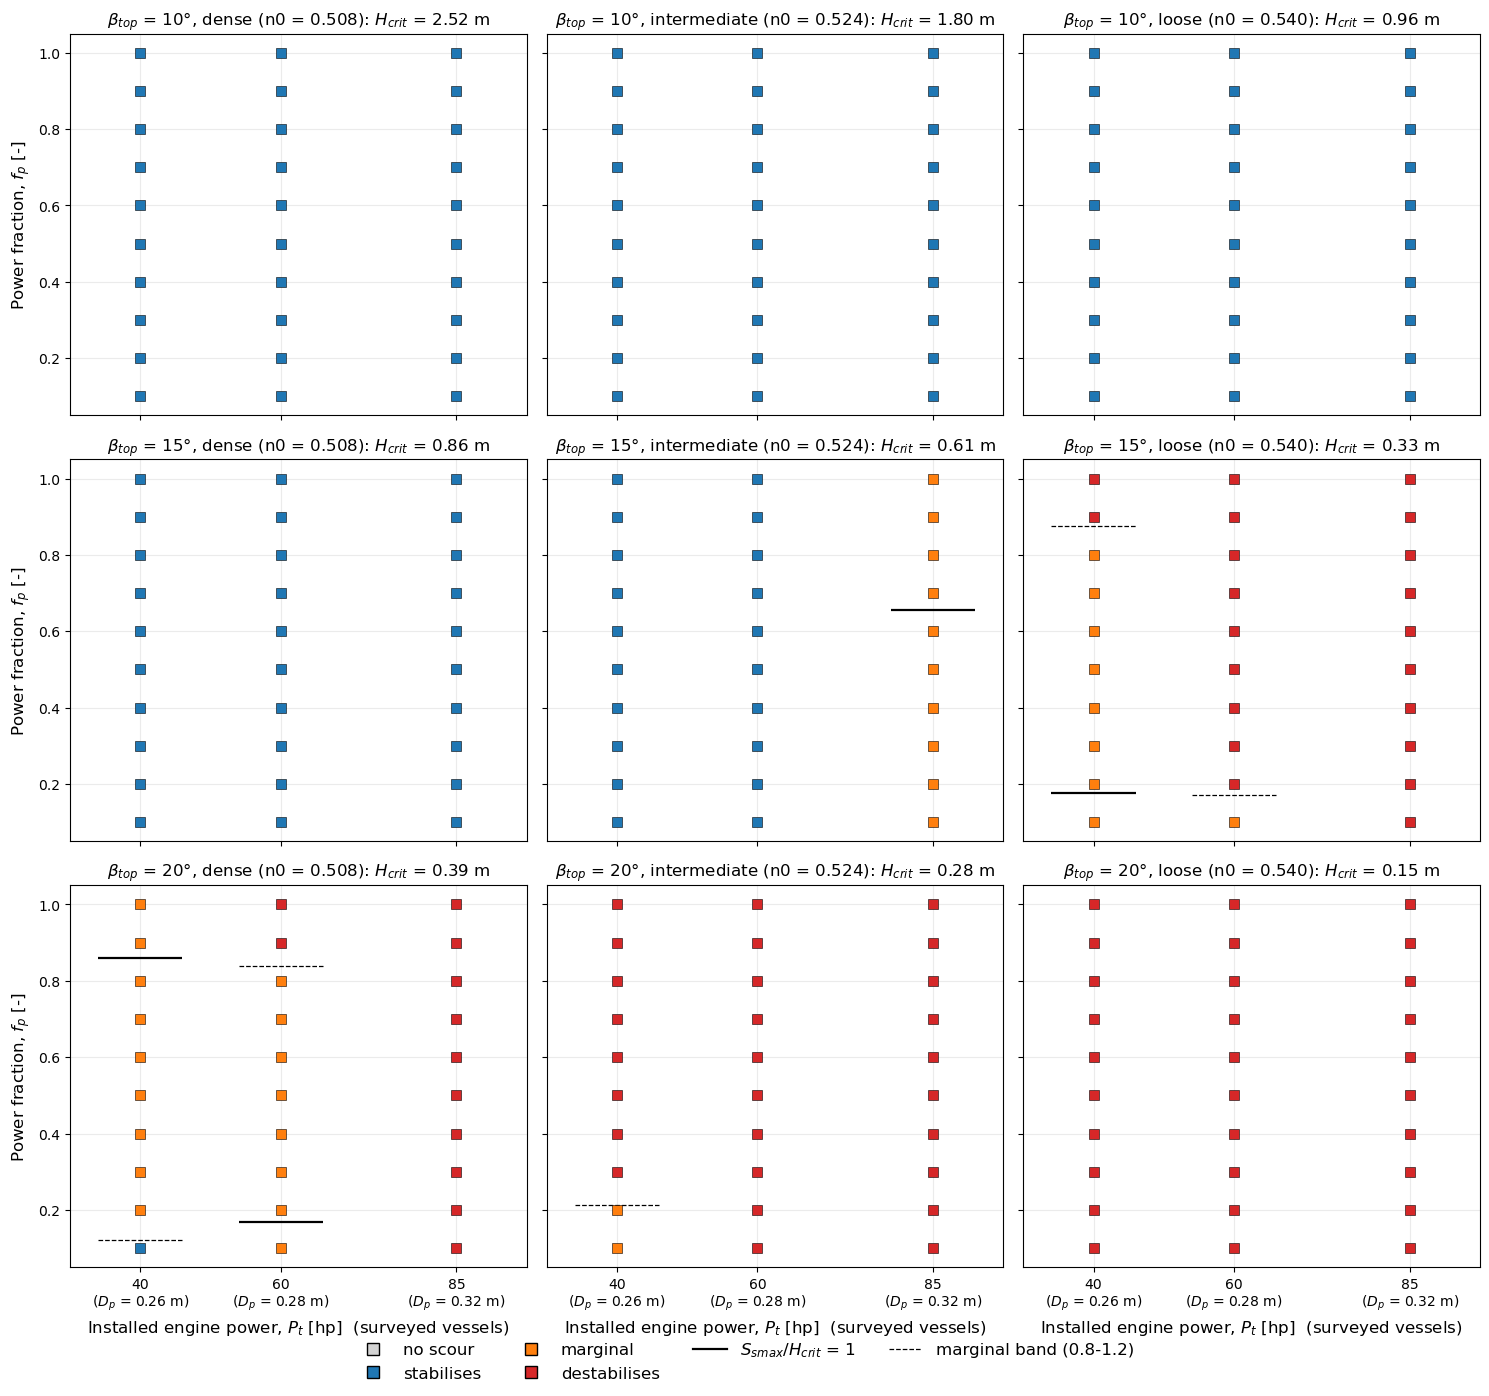

,beta_top [deg],n0 case,n0,H_crit [m],S_smax [m],destabilises / marginal / stabilises [%],lowest Pt that destabilises at full power [hp],lowest fp that destabilises at 85 hp
0,10.0,dense,0.508,2.52,0.31-0.64,0 / 0 / 100,-,-
1,10.0,intermediate,0.524,1.80,0.31-0.64,0 / 0 / 100,-,-
2,10.0,loose,0.540,0.96,0.31-0.64,0 / 0 / 100,-,-
3,15.0,dense,0.508,0.86,0.31-0.64,0 / 0 / 100,-,-
4,15.0,intermediate,0.524,0.61,0.31-0.64,0 / 33 / 67,-,-
5,15.0,loose,0.540,0.33,0.31-0.64,70 / 30 / 0,40.0,0.1
6,20.0,dense,0.508,0.39,0.31-0.64,40 / 57 / 3,60.0,0.1
7,20.0,intermediate,0.524,0.28,0.31-0.64,93 / 7 / 0,40.0,0.1
8,20.0,loose,0.540,0.15,0.31-0.64,100 / 0 / 0,40.0,0.1


In [9]:
# regime plot per slope angle (rows) and n0 case (columns)
case_tables = {}
fig, axes = plt.subplots(len(BETA_TOP_LEVELS), len(SOIL_CASES), figsize=(15, 14), sharex=True, sharey=True)
for row, bt in zip(axes, BETA_TOP_LEVELS):
    for ax, (case, soil) in zip(row, SOIL_CASES.items()):
        coarse = regime_table(soil, bt).assign(n0_case=case)
        fine = regime_table(soil, bt, fp_vals=FINE_FP, dx=0.01)
        case_tables[(bt, case)] = coarse
        draw_regime(ax, coarse, fine)
        ax.set_title(f'$\\beta_{{top}}$ = {bt:g}°, {case} (n0 = {soil.n0:.3f}): $H_{{crit}}$ = {coarse["H_crit"].iloc[0]:.2f} m',
                     fontsize=12)
for ax in axes[-1]:
    ax.set_xlabel('Installed engine power, $P_t$ [hp]  (surveyed vessels)', fontsize=12)
for ax in axes[:, 0]:
    ax.set_ylabel('Power fraction, $f_p$ [-]', fontsize=12)
regime_legend(fig, hatched=any(t['out_of_range'].any() for t in case_tables.values()))
fig.tight_layout(rect=(0, 0.03, 1, 1))
fig.savefig('sensitivity_slope_angle_n0.png', dpi=200)
plt.show()

pd.DataFrame([boundary_summary(t) for t in case_tables.values()])

## 8. Breach length, volume, released mass and duration

Ranges per mode, at 1 significant figure; released dry mass per metre width m = V (1 − n0) ρ_s (upper bound). ≥: the breach reached the still water level (x_max), so the values are lower bounds.

In [10]:
def event_sediment_release(volume_per_m, soil: SoilParams):
    '''Dry sand mass per breach event per metre width [kg/m]: m = V * (1 - n0) * rho_s'''
    return volume_per_m * (1 - soil.n0) * soil.rho_s


def value_range(s: pd.Series) -> str:
    '''min-max of s at 1 significant figure; '-' if empty'''
    if s.empty:
        return '-'
    lo, hi = (f'{float(f"{x:.1g}"):g}' for x in (s.min(), s.max()))
    return lo if lo == hi else f'{lo}-{hi}'


def capped_range(g: pd.DataFrame, fmt) -> str:
    '''fmt(g) as a range, with '≥' for the configurations that reached the still water level'''
    capped = g['reached_top']
    if capped.all():
        return '≥' + fmt(g)
    free = fmt(g[~capped])
    return f'{free}, ≥{fmt(g[capped])}' if capped.any() else free


def breach_magnitude_table(tables: dict) -> pd.DataFrame:
    '''Breach length, volume, released mass and duration per slope angle, n0 case and mode'''
    rows = []
    for (bt, case), t in tables.items():
        soil = SOIL_CASES[case]
        for mode in ('destabilises', 'marginal', 'stabilises'):
            g = t[t['mode'] == mode].assign(mass_per_m=lambda d: event_sediment_release(d['volume_per_m'], soil))
            if g.empty:
                continue
            rows.append({'beta_top [deg]': bt, 'n0 case': case, 'mode': mode,
                         'configurations [%]': round(100 * len(g) / len(t)),
                         'breach length L [m]': capped_range(g, lambda d: value_range(d['retreat'])),
                         'volume V [m3/m]': capped_range(g, lambda d: value_range(d['volume_per_m'])),
                         'released mass m [kg/m]': capped_range(g, lambda d: value_range(d['mass_per_m'])),
                         'duration T [s]': capped_range(g, lambda d: value_range(d['duration']))})
    return pd.DataFrame(rows)


breach_magnitude_table(case_tables)

,beta_top [deg],n0 case,mode,configurations [%],breach length L [m],volume V [m3/m],released mass m [kg/m],duration T [s]
0,10.0,dense,stabilises,100,0.9-3,0.2-1,200-2000,80-300
1,10.0,intermediate,stabilises,100,1-4,0.2-2,300-2000,70-200
2,10.0,loose,stabilises,100,"2-4, ≥5","0.3-1, ≥2-3","400-2000, ≥2000-3000","60-100, ≥100"
3,15.0,dense,stabilises,100,"1-3, ≥3","0.2-0.9, ≥1-2","300-1000, ≥1000-2000","100-300, ≥300"
4,15.0,intermediate,marginal,33,≥3,≥1-2,≥2000-3000,≥200
5,15.0,intermediate,stabilises,67,"2-3, ≥3","0.4-0.8, ≥0.8-1","500-1000, ≥1000-2000","100-200, ≥200"
6,15.0,loose,destabilises,70,≥3,≥1-2,≥2000-3000,≥100
7,15.0,loose,marginal,30,≥3,≥0.9-1,≥1000-2000,≥100
8,20.0,dense,destabilises,40,≥2,≥1-2,≥2000,≥200
9,20.0,dense,marginal,57,≥2,≥0.6-1,≥900-1000,≥200


## 9. Field experiment: OBS measurements against the scour equation

Experiment vessel: 85 hp, Dp = 0.30 m, z_p = 0.30 m, in sand similar to the spit (soil_sisal). The vessel was speed-controlled, so the power fraction per manoeuvre follows from the speed: fp = v / v_max with v_max = 25 km/h. Left axis: S_smax of the experiment vessel at that fp [eq:Scour]. Right axis: peak OBS value per manoeuvre.

Experiment vessel: 85 hp, Dp = 0.30 m, z_p = 0.30 m, G = 0.50 m, G/Dp = 1.67 (tested 0.77-3.08), Frd at fp = 1: 215 (tested 1.89-15.01)


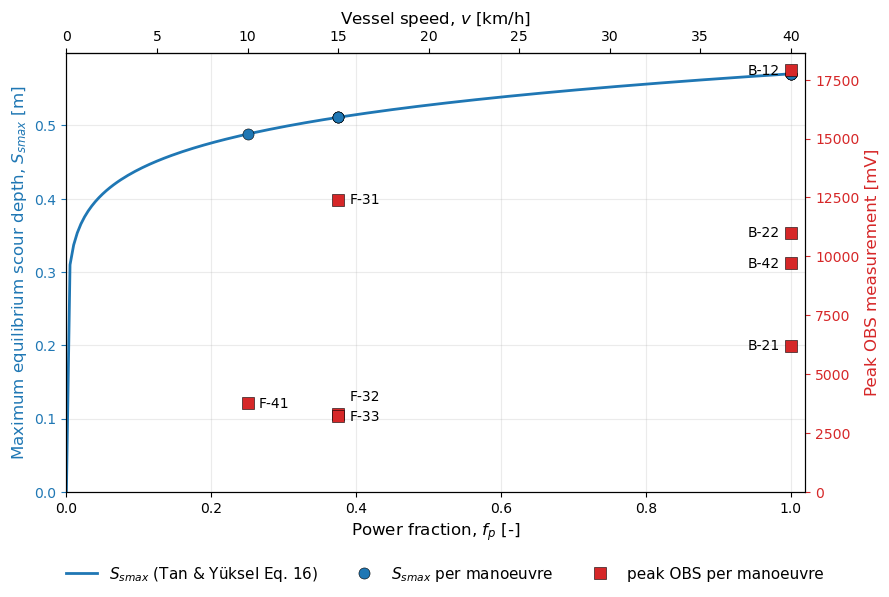

,manoeuvre,v_kmh,fp,S_smax,obs_peak
0,F-31,15.0,0.375,0.511,12400
1,F-32,15.0,0.375,0.511,3300
2,F-33,15.0,0.375,0.511,3200
3,F-41,10.0,0.250,0.488,3750
4,B-12,40.0,1.000,0.571,17900
5,B-22,40.0,1.000,0.571,11000
6,B-42,40.0,1.000,0.571,9700
7,B-21,40.0,1.000,0.571,6200


In [11]:
# -----------------------------------------------------------------------------
# 9a. Field experiment inputs
# -----------------------------------------------------------------------------
EXP_VESSEL = VesselParams(Pt_hp=85.0, Dp=0.30, rho_w=soil_sisal.rho_w)   # experiment vessel (not a surveyed case)
EXP_AXIS_DEPTH = 0.30       # [m]    propeller axis depth z_p
EXP_H_TOE = H_TOE           # [m]    water depth during the experiment (still water level, no tide)
EXP_V_MAX = 40.0            # [km/h] vessel speed at full power (fp = 1)
OBS_UNIT = 'mV'             # [-]    unit of the OBS values

# Manoeuvres: target speed and peak OBS value
EXP_MANOEUVRES = pd.DataFrame({
    'manoeuvre': ['F-31', 'F-32', 'F-33', 'F-41', 'B-12', 'B-22', 'B-42', 'B-21'],
    'v_kmh':     [15.0, 15.0, 15.0, 10.0, 40.0, 40.0, 40.0, 40.0],        # [km/h] target speed
    'obs_peak':  [12400, 3300, 3200, 3750, 17900, 11000, 9700, 6200],     # [OBS_UNIT] peak OBS value
})


def experiment_scour(fp: float) -> float:
    '''S_smax [m] of the experiment vessel at power fraction fp [eq:Scour]'''
    return equilibrium_scour_depth(replace(EXP_VESSEL, fp=fp), soil_sisal, clearance(EXP_H_TOE, EXP_AXIS_DEPTH))


# -----------------------------------------------------------------------------
# 9b. Figure: model scour depth (left) and peak OBS (right) against fp = v / v_max
# -----------------------------------------------------------------------------
G_exp = clearance(EXP_H_TOE, EXP_AXIS_DEPTH)
exp = EXP_MANOEUVRES.assign(fp=lambda d: d['v_kmh'] / EXP_V_MAX)
exp['S_smax'] = [experiment_scour(fp) for fp in exp['fp']]
fp_line = np.linspace(0, 1, 201)
S_line = [experiment_scour(fp) for fp in fp_line]

print(f"Experiment vessel: {EXP_VESSEL.Pt_hp:g} hp, Dp = {EXP_VESSEL.Dp:.2f} m, z_p = {EXP_AXIS_DEPTH:.2f} m, "
      f"G = {G_exp:.2f} m, G/Dp = {G_exp/EXP_VESSEL.Dp:.2f} (tested {TY_GDP_RANGE[0]:g}-{TY_GDP_RANGE[1]:g}), "
      f"Frd at fp = 1: {densimetric_froude(EXP_VESSEL, soil_sisal):.0f} (tested {TY_FRD_RANGE[0]:g}-{TY_FRD_RANGE[1]:g})")

fig, ax = plt.subplots(figsize=(9, 6))
ax.plot(fp_line, S_line, color='tab:blue', lw=2, label='$S_{smax}$ (Tan & Yüksel Eq. 16)')
ax.plot(exp['fp'], exp['S_smax'], 'o', color='tab:blue', ms=8, markeredgecolor='k', mew=0.4, zorder=3,
        label='$S_{smax}$ per manoeuvre')
ax.set_xlabel('Power fraction, $f_p$ [-]', fontsize=12)
ax.set_ylabel('Maximum equilibrium scour depth, $S_{smax}$ [m]', fontsize=12, color='tab:blue')
ax.tick_params(axis='y', colors='tab:blue')
ax.set_xlim(0, 1.02)
ax.set_ylim(bottom=0)
ax.grid(alpha=0.25)

ax_v = ax.secondary_xaxis('top', functions=(lambda fp: fp * EXP_V_MAX, lambda v: v / EXP_V_MAX))
ax_v.set_xlabel('Vessel speed, $v$ [km/h]', fontsize=12)

ax_obs = ax.twinx()
ax_obs.plot(exp['fp'], exp['obs_peak'], 's', color='tab:red', ms=8, markeredgecolor='k', mew=0.4, zorder=3,
            label='peak OBS per manoeuvre')
ax_obs.set_ylabel(f'Peak OBS measurement [{OBS_UNIT}]', fontsize=12, color='tab:red')
ax_obs.tick_params(axis='y', colors='tab:red')
ax_obs.set_ylim(bottom=0)

# Manoeuvre labels next to the squares; labels at the same fp are pushed apart vertically
min_gap = 0.045 * ax_obs.get_ylim()[1]
for fp, g in exp.sort_values('obs_peak').groupby('fp'):
    left = fp > 0.9                             # keep labels near fp = 1 inside the axes
    shift = offset_copy(ax_obs.transData, fig=fig, x=-8 if left else 8, units='points')
    y_label = -np.inf
    for _, r in g.iterrows():
        y_label = max(r['obs_peak'], y_label + min_gap)
        ax_obs.text(fp, y_label, r['manoeuvre'], transform=shift, ha='right' if left else 'left',
                    va='center', fontsize=10)

handles = ax.get_legend_handles_labels()[0] + ax_obs.get_legend_handles_labels()[0]
fig.legend(handles=handles, loc='lower center', ncol=3, fontsize=11, frameon=False)
fig.tight_layout(rect=(0, 0.06, 1, 1))
fig.savefig('obs_vs_scour_depth.png', dpi=200)
plt.show()

exp[['manoeuvre', 'v_kmh', 'fp', 'S_smax', 'obs_peak']].round(3)